# Détection de fraude : modèles supervisés (version corrigée, MLflow intégré)

**Ce que fait ce notebook** : entraîne Logistic Regression, Random Forest et XGBoost avec 3 stratégies de gestion du déséquilibre (baseline, pondération des classes, SMOTENC) et enregistre **chaque run dans MLflow**.

**Corrections par rapport à la version précédente**
1. **Cohérence des variables** : liste blanche de variables *connues avant la transaction*. Le tag `feature_set` est maintenant vérifié par le code, il ne peut plus être faux. Avant, la baseline MLflow pouvait être entraînée avec `newbalanceOrig`/`newbalanceDest` tout en étant taguée « sans post-transaction ».
2. **Plus de doublons** : une seule boucle entraîne et trace chaque modèle. Une ré-exécution met les anciens runs de même clé à la corbeille MLflow (restaurable).
3. **Validation temporelle** : les derniers 15 % de la période d'entraînement servent à choisir le seuil. Le test n'est jamais utilisé pour ça.
4. **`step` remplacé par `hour_of_day`** : avec un découpage temporel, le test contient des `step` jamais vus à l'entraînement. Mettre `USE_RAW_STEP = True` pour revenir au comportement précédent.
5. **Bug corrigé** : `trained_models` était utilisé sans être défini.

**Ajouts** : seuil optimisé sur validation, rappel/précision au top-k (budget d'alertes), `Amount_Recall` (part du montant frauduleux retrouvée), importance des variables, courbes et table de seuils pour le tableau de bord.

In [1]:
from pathlib import Path

NOTEBOOK_NAME = "supervised_fraud_detection"

# ---------- Données
DATA_PATH = Path("../data/processed/fraud_eda_features.parquet")
DATASET_VERSION = "paysim_v1"       # à changer si les données ou le prétraitement changent

# ---------- MLflow
TRACKING_URI = "sqlite:///mlflow.db"
EXPERIMENT_NAME = "Fraud_Detection_Experiments"
LOG_MODELS = True                   # False = plus rapide, n'enregistre pas les pipelines
REPLACE_PREVIOUS_RUNS = True        # anciens runs de même clé -> corbeille MLflow (restaurable)

# ---------- Découpage temporel (identique dans les deux notebooks)
RANDOM_STATE = 42
TEST_FRACTION = 0.20                # derniers 20 % des lignes (dans le temps)
VAL_FRACTION_OF_TRAIN = 0.15        # derniers 15 % de la période d'entraînement : choix du seuil
USE_RAW_STEP = False                # False : on remplace `step` par `hour_of_day` (voir note)
TOP_K_FRACTIONS = [0.001, 0.005, 0.01]   # budgets d'alertes : top 0,1 % / 0,5 % / 1 % des scores

# ---------- Spécifique à ce notebook
TRAIN_SAMPLE_SIZE = 1_000_000       # échantillon stratifié de la période d'entraînement
SMOTE_SAMPLING_STRATEGY = 0.1       # ratio fraude / normal après SMOTENC
STRATEGIES = ["baseline", "class_weighting", "SMOTENC"]

# ---------- Test rapide (vérifier que tout tourne avant le vrai run)
QUICK_RUN = False
QUICK_RUN_ROWS = 200_000

In [2]:
# ============================================================
# SOCLE COMMUN : cellule identique dans les deux notebooks.
# Elle fixe le "contrat" MLflow lu par le tableau de bord :
# mêmes tags, mêmes noms de métriques, mêmes artefacts.
# ============================================================
import tempfile
import time
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow.tracking import MlflowClient
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

# ---------- Variables : uniquement des informations connues AVANT la transaction
TARGET = "isFraud"
CATEGORICAL_FEATURES = ["type"]
NUMERIC_FEATURES = [
    "amount", "oldbalanceOrg", "oldbalanceDest",
    "amount_nul", "ratioOrig_nul", "ratioDest_nul", "hour_of_day",
]
if USE_RAW_STEP:
    NUMERIC_FEATURES = ["step"] + NUMERIC_FEATURES
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
# colonnes calculées APRÈS la transaction (fuite de données si utilisées)
POST_TRANSACTION_PATTERNS = ("newbalance", "ecart")


# ---------------------------------------------------------------
# Données et découpage temporel : fit (entraînement) / val / test
# ---------------------------------------------------------------
def load_dataset():
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Fichier introuvable : {DATA_PATH.resolve()}")
    df = pd.read_parquet(DATA_PATH)
    if QUICK_RUN and len(df) > QUICK_RUN_ROWS:
        df = df.sample(QUICK_RUN_ROWS, random_state=RANDOM_STATE)
    df = df.sort_values("step", kind="mergesort").reset_index(drop=True)
    df["hour_of_day"] = df["step"] % 24          # 1 step = 1 heure dans PaySim
    missing = [c for c in FEATURES + [TARGET] if c not in df.columns]
    if missing:
        raise KeyError(f"Colonnes manquantes dans le parquet : {missing}")
    for col in NUMERIC_FEATURES:
        if pd.api.types.is_bool_dtype(df[col]):
            df[col] = df[col].astype("int8")
    return df


def audit_features(df):
    leaking = [c for c in FEATURES if any(p in c.lower() for p in POST_TRANSACTION_PATTERNS)]
    if leaking:
        raise ValueError(f"Variables post-transaction détectées dans FEATURES : {leaking}")
    excluded = [c for c in df.columns if c not in FEATURES]
    print("Variables utilisées :", FEATURES)
    print("Variables exclues   :", excluded)
    return "pre_transaction"


def temporal_split(df):
    cut_test = int(len(df) * (1 - TEST_FRACTION))
    step_test = df["step"].iloc[cut_test]
    train_period = df[df["step"] < step_test]
    test_df = df[df["step"] >= step_test]

    cut_val = int(len(train_period) * (1 - VAL_FRACTION_OF_TRAIN))
    step_val = train_period["step"].iloc[cut_val]
    fit_df = train_period[train_period["step"] < step_val]
    val_df = train_period[train_period["step"] >= step_val]

    for name, part in [("fit", fit_df), ("val", val_df), ("test", test_df)]:
        if part.empty or part[TARGET].sum() == 0:
            raise ValueError(f"Le jeu '{name}' est vide ou ne contient aucune fraude.")
    assert fit_df["step"].max() < val_df["step"].min()
    assert val_df["step"].max() < test_df["step"].min()
    info = {"step_val_start": int(step_val), "step_test_start": int(step_test)}
    return fit_df.copy(), val_df.copy(), test_df.copy(), info


def describe_splits(**parts):
    rows = []
    for name, part in parts.items():
        rows.append({
            "jeu": name, "lignes": len(part),
            "fraudes": int(part[TARGET].sum()),
            "taux_fraude_%": round(part[TARGET].mean() * 100, 4),
            "step_min": int(part["step"].min()), "step_max": int(part["step"].max()),
        })
    return pd.DataFrame(rows)


def build_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler(with_mean=False)),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ])


# ---------------------------------------------------------------
# Métriques
# ---------------------------------------------------------------
def _frac_name(f):
    return f"{f * 100:g}".replace(".", "p")


def ranking_metrics(y_true, scores):
    # métriques indépendantes du seuil : PR_AUC, ROC_AUC et rappel / précision au top-k
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    m = {
        "PR_AUC": average_precision_score(y_true, scores),
        "ROC_AUC": roc_auc_score(y_true, scores),
    }
    y_sorted = y_true[np.argsort(-scores, kind="mergesort")]
    n, n_pos = len(y_true), int(y_true.sum())
    for f in TOP_K_FRACTIONS:
        k = max(1, int(round(n * f)))
        tp_k = int(y_sorted[:k].sum())
        m[f"Recall_top_{_frac_name(f)}pct"] = tp_k / n_pos if n_pos else 0.0
        m[f"Precision_top_{_frac_name(f)}pct"] = tp_k / k
    return m


def threshold_metrics(y_true, scores, threshold, amounts=None, suffix=""):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Alerts": int(tp + fp),
        "Alert_rate": (tp + fp) / len(y_true),
    }
    if amounts is not None:
        amounts = np.asarray(amounts, dtype=float)
        fraud_total = amounts[y_true == 1].sum()
        caught = amounts[(y_true == 1) & (y_pred == 1)].sum()
        m["Amount_Recall"] = float(caught / fraud_total) if fraud_total > 0 else 0.0
    return {f"{k}{suffix}": v for k, v in m.items()}, y_pred


def threshold_table(y_true, scores, n_low=60, n_high=140):
    # table seuil -> TP/FP/FN/TN/précision/rappel, pour le curseur de seuil du tableau de bord
    y = np.asarray(y_true).astype(int)
    s = np.asarray(scores, dtype=float)
    order = np.argsort(s, kind="mergesort")
    s_sorted, y_sorted = s[order], y[order]
    cum_pos = np.concatenate([[0], np.cumsum(y_sorted)])
    n, n_pos = len(y), int(y.sum())
    qs = np.concatenate([np.linspace(0, 0.99, n_low, endpoint=False), np.linspace(0.99, 1.0, n_high)])
    thr = np.unique(np.quantile(s, qs))
    idx = np.searchsorted(s_sorted, thr, side="left")
    flagged = n - idx
    tp = n_pos - cum_pos[idx]
    fp = flagged - tp
    fn = n_pos - tp
    tn = (n - n_pos) - fp
    precision = np.divide(tp, flagged, out=np.zeros(len(tp), dtype=float), where=flagged > 0)
    recall = tp / n_pos if n_pos else np.zeros(len(tp))
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros(len(tp), dtype=float), where=denom > 0)
    return pd.DataFrame({
        "threshold": thr, "flagged": flagged, "alert_rate": flagged / n,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": precision, "Recall": recall, "F1": f1,
    })


def _downsample(x, y, n=500):
    if len(x) <= n:
        return x, y
    idx = np.unique(np.linspace(0, len(x) - 1, n).astype(int))
    return x[idx], y[idx]


def curve_frames(y_true, scores):
    p, r, _ = precision_recall_curve(y_true, scores)
    r_d, p_d = _downsample(r, p)
    fpr, tpr, _ = roc_curve(y_true, scores)
    f_d, t_d = _downsample(fpr, tpr)
    return (pd.DataFrame({"recall": r_d, "precision": p_d}),
            pd.DataFrame({"fpr": f_d, "tpr": t_d}))


def plot_confusion(y_true, y_pred, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1], display_labels=["Normal", "Fraude"],
        ax=ax, cmap="Blues", values_format=",d",
    )
    ax.set_title(title)
    fig.tight_layout()
    return fig


def plot_pr(pr_df, title, pr_auc):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(pr_df["recall"], pr_df["precision"])
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(f"{title} (PR-AUC = {pr_auc:.4f})")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------
# MLflow
# ---------------------------------------------------------------
mlflow.set_tracking_uri(TRACKING_URI)
_experiment = mlflow.set_experiment(EXPERIMENT_NAME)
EXPERIMENT_ID = _experiment.experiment_id
client = MlflowClient()
BATCH_ID = datetime.now().strftime("%Y%m%d_%H%M%S")


def archive_previous_runs(run_key):
    # envoie à la corbeille MLflow (restaurable) les anciens runs de même clé :
    # une ré-exécution du notebook ne crée donc pas de doublons dans le tableau de bord
    if not REPLACE_PREVIOUS_RUNS:
        return 0
    old = client.search_runs([EXPERIMENT_ID], filter_string=f"tags.run_key = '{run_key}'", max_results=1000)
    for r in old:
        client.delete_run(r.info.run_id)
    return len(old)


def _log_model(model, x_example):
    kwargs = dict(serialization_format="cloudpickle", input_example=x_example)
    try:                                              # MLflow >= 3
        mlflow.sklearn.log_model(model, name="model", **kwargs)
    except TypeError:                                 # MLflow 2.x
        mlflow.sklearn.log_model(model, artifact_path="model", **kwargs)


def log_full_run(*, run_name, tags, params, thresholds, y_true, scores, amounts=None,
                 extra_metrics=None, model=None, x_example=None, importance=None, title=""):
    # thresholds : {suffixe: seuil}. Le suffixe "" correspond au seuil principal.
    y_true = np.asarray(y_true).astype(int)
    metrics = dict(ranking_metrics(y_true, scores))
    preds = {}
    for suffix, thr in thresholds.items():
        m, y_pred = threshold_metrics(y_true, scores, thr, amounts, suffix)
        metrics.update(m)
        preds[suffix] = y_pred
    if extra_metrics:
        metrics.update(extra_metrics)

    pr_df, roc_df = curve_frames(y_true, scores)
    table = threshold_table(y_true, scores)
    n_archived = archive_previous_runs(tags["run_key"])

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({**tags, "batch_id": BATCH_ID, "dataset_version": DATASET_VERSION,
                         "notebook": NOTEBOOK_NAME})
        mlflow.log_params({k: str(v)[:250] for k, v in params.items()})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()
                            if v is not None and np.isfinite(v)})

        with tempfile.TemporaryDirectory() as tmp:
            tmp = Path(tmp)

            def _log(path):
                mlflow.log_artifact(str(path), artifact_path="evaluation")

            for suffix, y_pred in preds.items():
                label = suffix or "_seuil_principal"
                fig = plot_confusion(y_true, y_pred, f"{title} | {label.strip('_')}")
                p = tmp / f"confusion_matrix{suffix}.png"
                fig.savefig(p, dpi=150)
                plt.close(fig)
                _log(p)
                cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                p = tmp / f"confusion_matrix{suffix}.csv"
                pd.DataFrame(cm, index=["Actual_Normal", "Actual_Fraud"],
                             columns=["Predicted_Normal", "Predicted_Fraud"]).to_csv(p)
                _log(p)

            fig = plot_pr(pr_df, title, metrics["PR_AUC"])
            p = tmp / "pr_curve.png"
            fig.savefig(p, dpi=150)
            plt.close(fig)
            _log(p)

            for name, frame in [("pr_curve_points", pr_df), ("roc_curve_points", roc_df),
                                ("threshold_table", table)]:
                p = tmp / f"{name}.csv"
                frame.to_csv(p, index=False)
                _log(p)

            if importance is not None:
                p = tmp / "feature_importance.csv"
                importance.to_csv(p, index=False)
                _log(p)

        if model is not None and LOG_MODELS:
            _log_model(model, x_example)

    if n_archived:
        print(f"   ({n_archived} ancien(s) run(s) de même clé mis à la corbeille MLflow)")
    return run.info.run_id, metrics


# ---------------------------------------------------------------
# Lecture du classement depuis MLflow (même fonction que le tableau de bord)
# ---------------------------------------------------------------
LEADERBOARD_TAGS = ["family", "model", "strategy", "purpose", "contamination",
                    "is_reference", "feature_set", "batch_id", "dataset_version"]
LEADERBOARD_METRICS = [
    "PR_AUC", "ROC_AUC", "Precision", "Recall", "F1", "MCC", "Amount_Recall", "Alert_rate",
    "Recall_top_0p1pct", "Precision_top_0p1pct", "Recall_top_0p5pct", "Recall_top_1pct",
    "Precision_tuned", "Recall_tuned", "F1_tuned",
    "Training_time_sec", "Prediction_time_sec",
]


def load_leaderboard(dataset_version=None, only_reference=False):
    dv = dataset_version or DATASET_VERSION
    runs = mlflow.search_runs(
        experiment_ids=[EXPERIMENT_ID],
        filter_string=f"tags.dataset_version = '{dv}'",
        output_format="pandas",
    )
    if runs.empty:
        return pd.DataFrame()

    def col(key):
        return runs[key] if key in runs.columns else pd.Series(np.nan, index=runs.index)

    out = pd.DataFrame({"run_id": runs["run_id"], "run_name": col("tags.mlflow.runName")})
    for t in LEADERBOARD_TAGS:
        out[t] = col(f"tags.{t}")
    for m in LEADERBOARD_METRICS:
        out[m] = col(f"metrics.{m}")
    if only_reference:
        out = out[out["is_reference"] == "true"]
    return out.sort_values("PR_AUC", ascending=False).reset_index(drop=True)


print(f"MLflow : {TRACKING_URI} | expérience '{EXPERIMENT_NAME}' (id={EXPERIMENT_ID}) | batch {BATCH_ID}")

MLflow : sqlite:///mlflow.db | expérience 'Fraud_Detection_Experiments' (id=1) | batch 20261030_220326


## 1. Chargement, audit des variables et découpage temporel

In [3]:
from sklearn.model_selection import train_test_split

df = load_dataset()
FEATURE_SET = audit_features(df)
fit_full, val_df, test_df, split_info = temporal_split(df)

# échantillon stratifié de la période d'entraînement (comme avant, mais sans toucher à val/test)
if len(fit_full) > TRAIN_SAMPLE_SIZE:
    fit_df, _ = train_test_split(fit_full, train_size=TRAIN_SAMPLE_SIZE,
                                 stratify=fit_full[TARGET], random_state=RANDOM_STATE)
else:
    fit_df = fit_full

X_fit, y_fit = fit_df[FEATURES], fit_df[TARGET].astype("int8")
X_val, y_val = val_df[FEATURES], val_df[TARGET].astype("int8")
X_test, y_test = test_df[FEATURES], test_df[TARGET].astype("int8")
test_amounts = test_df["amount"].to_numpy()

print()
display(describe_splits(fit=fit_df, val=val_df, test=test_df))
print("Seuils temporels :", split_info)

Variables utilisées : ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_nul', 'ratioOrig_nul', 'ratioDest_nul', 'hour_of_day', 'type']
Variables exclues   : ['step', 'nameOrig', 'newbalanceOrig', 'nameDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'ecartOrig', 'ecartDest', 'ratioOrig', 'ratioDest']



,jeu,lignes,fraudes,taux_fraude_%,step_min,step_max
0,fit,1000000,810,0.0810,1,306
1,val,805818,500,0.0620,307,354
2,test,1293523,4258,0.3292,355,743


Seuils temporels : {'step_val_start': 307, 'step_test_start': 355}


## 2. Modèles et pipelines

In [4]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer
from xgboost import XGBClassifier

SCALE_POS_WEIGHT = float((y_fit == 0).sum() / max(int((y_fit == 1).sum()), 1))
print(f"scale_pos_weight (calculé sur le jeu d'entraînement uniquement) : {SCALE_POS_WEIGHT:.1f}")


def cast_numeric_columns(X, numeric_cols):
    # SMOTENC peut renvoyer des colonnes numériques en `object` : on les remet en float
    X = pd.DataFrame(X).copy()
    X[numeric_cols] = X[numeric_cols].astype(float)
    return X


def make_estimators(strategy):
    weighted = strategy == "class_weighting"
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1000, random_state=RANDOM_STATE,
            class_weight="balanced" if weighted else None),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=16, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1,
            class_weight="balanced_subsample" if weighted else None),
        "XGBoost": XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist",
            scale_pos_weight=SCALE_POS_WEIGHT if weighted else 1.0,
            random_state=RANDOM_STATE, n_jobs=-1),
    }


def make_pipeline(strategy, estimator):
    if strategy == "SMOTENC":
        # le rééquilibrage n'est appliqué qu'à l'entraînement (jamais à val/test)
        return ImbPipeline([
            ("smote", SMOTENC(categorical_features=CATEGORICAL_FEATURES,
                              sampling_strategy=SMOTE_SAMPLING_STRATEGY,
                              k_neighbors=5, random_state=RANDOM_STATE)),
            ("cast", FunctionTransformer(cast_numeric_columns,
                                         kw_args={"numeric_cols": NUMERIC_FEATURES})),
            ("preprocessor", build_preprocessor()),
            ("model", estimator),
        ])
    return Pipeline([("preprocessor", build_preprocessor()), ("model", estimator)])


def best_f1_threshold(y_true, scores):
    # seuil qui maximise le F1 sur le jeu de VALIDATION (jamais sur le test)
    p, r, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])


def feature_importance_df(pipe):
    try:
        names = pipe.named_steps["preprocessor"].get_feature_names_out()
        est = pipe.named_steps["model"]
        if hasattr(est, "feature_importances_"):
            imp = est.feature_importances_
        elif hasattr(est, "coef_"):
            imp = np.abs(est.coef_).ravel()
        else:
            return None
        return pd.DataFrame({"feature": names, "importance": imp}).sort_values(
            "importance", ascending=False)
    except Exception:
        return None


if "SMOTENC" in STRATEGIES and X_fit.isna().sum().sum() > 0:
    raise ValueError("SMOTENC n'accepte pas les valeurs manquantes : imputez X_fit avant.")

scale_pos_weight (calculé sur le jeu d'entraînement uniquement) : 1233.6


## 3. Entraînement et suivi MLflow

Un run par couple (modèle, stratégie). Compter plusieurs minutes avec `TRAIN_SAMPLE_SIZE = 1_000_000`.

In [5]:
all_results, trained_models, test_scores = [], {}, {}

for strategy in STRATEGIES:
    for model_name, estimator in make_estimators(strategy).items():
        label = f"{model_name} | {strategy}"
        print(f"\n{'=' * 70}\n{label}")

        pipe = make_pipeline(strategy, estimator)

        t0 = time.time()
        pipe.fit(X_fit, y_fit)
        train_time = time.time() - t0

        t1 = time.time()
        proba_test = pipe.predict_proba(X_test)[:, 1]
        pred_time = time.time() - t1
        proba_val = pipe.predict_proba(X_val)[:, 1]

        thr_tuned, val_f1 = best_f1_threshold(y_val, proba_val)

        params = {
            "algorithm": model_name, "strategy": strategy, "feature_set": FEATURE_SET,
            "features": ",".join(FEATURES), "threshold": 0.5, "tuned_threshold": round(thr_tuned, 6),
            "fit_size": len(X_fit), "val_size": len(X_val), "test_size": len(X_test),
            "n_fraud_fit": int(y_fit.sum()), "n_fraud_test": int(y_test.sum()),
            "random_state": RANDOM_STATE, "use_raw_step": USE_RAW_STEP,
            "step_val_start": split_info["step_val_start"], "step_test_start": split_info["step_test_start"],
            "smote_sampling_strategy": SMOTE_SAMPLING_STRATEGY if strategy == "SMOTENC" else "none",
            "scale_pos_weight": round(SCALE_POS_WEIGHT, 2) if strategy == "class_weighting" else "none",
            **{f"model_{k}": v for k, v in estimator.get_params(deep=False).items()},
        }
        tags = {
            "family": "supervised", "model": model_name, "strategy": strategy,
            "purpose": "model_comparison", "feature_set": FEATURE_SET,
            "is_reference": "true",
            "run_key": f"supervised|{model_name}|{strategy}|{DATASET_VERSION}",
        }

        run_id, metrics = log_full_run(
            run_name=f"{strategy}_{model_name.replace(' ', '_')}",
            tags=tags, params=params,
            thresholds={"": 0.5, "_tuned": thr_tuned},
            y_true=y_test, scores=proba_test, amounts=test_amounts,
            extra_metrics={"Training_time_sec": train_time, "Prediction_time_sec": pred_time,
                           "Tuned_threshold": thr_tuned, "Val_F1_at_tuned_threshold": val_f1},
            model=pipe, x_example=X_fit.head(5),
            importance=feature_importance_df(pipe), title=label,
        )

        trained_models[label] = pipe
        test_scores[label] = proba_test
        all_results.append({"Model": model_name, "Strategy": strategy, "run_id": run_id, **metrics})

        print(f"PR-AUC {metrics['PR_AUC']:.4f} | seuil 0.5 -> F1 {metrics['F1']:.4f} "
              f"(Recall {metrics['Recall']:.4f}) | seuil optimisé -> F1 {metrics['F1_tuned']:.4f} "
              f"(Recall {metrics['Recall_tuned']:.4f}) | {train_time:.1f}s")

results_df = pd.DataFrame(all_results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)


Logistic Regression | baseline


2026/10/30 22:03:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC 0.6246 | seuil 0.5 -> F1 0.3736 (Recall 0.2297) | seuil optimisé -> F1 0.5677 (Recall 0.4023) | 1.7s

Random Forest | baseline


2026/10/30 22:04:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC 0.8699 | seuil 0.5 -> F1 0.8436 (Recall 0.7299) | seuil optimisé -> F1 0.8586 (Recall 0.7560) | 18.9s

XGBoost | baseline


2026/10/30 22:04:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (9 outputs left out)

2026/10/30 22:06:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC 0.8631 | seuil 0.5 -> F1 0.7835 (Recall 0.8175) | seuil optimisé -> F1 0.8370 (Recall 0.7313) | 27.5s

XGBoost | SMOTENC


2026/10/30 22:06:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC 0.8963 | seuil 0.5 -> F1 0.7330 (Recall 0.8762) | seuil optimisé -> F1 0.8574 (Recall 0.7553) | 11.4s


## 4. Résultats

In [6]:
cols = ["Model", "Strategy", "PR_AUC", "ROC_AUC", "Precision", "Recall", "F1", "MCC",
        "F1_tuned", "Recall_tuned", "Precision_tuned", "Amount_Recall",
        "Recall_top_0p1pct", "Recall_top_0p5pct", "Recall_top_1pct", "Training_time_sec"]
display(results_df[cols].round(4))

,Model,Strategy,PR_AUC,ROC_AUC,Precision,Recall,F1,MCC,F1_tuned,Recall_tuned,Precision_tuned,Amount_Recall,Recall_top_0p1pct,Recall_top_0p5pct,Recall_top_1pct,Training_time_sec
0,XGBoost,class_weighting,0.9172,0.9983,0.5585,0.9133,0.6932,0.7131,0.8723,0.7757,0.9964,0.9943,0.3039,0.9065,0.9495,6.7061
1,XGBoost,baseline,0.9165,0.9988,0.9943,0.7830,0.8761,0.8820,0.8823,0.7945,0.9918,0.9730,0.3039,0.9025,0.9486,5.7040
2,XGBoost,SMOTENC,0.8963,0.9979,0.6300,0.8762,0.7330,0.7420,0.8574,0.7553,0.9914,0.9896,0.3039,0.8849,0.9314,11.4287
3,Random Forest,baseline,0.8699,0.9949,0.9994,0.7299,0.8436,0.8537,0.8586,0.7560,0.9935,0.9624,0.3039,0.8565,0.8837,18.9355
4,Random Forest,SMOTENC,0.8631,0.9949,0.7522,0.8175,0.7835,0.7834,0.8370,0.7313,0.9783,0.9808,0.3039,0.8499,0.8971,27.5209
5,Random Forest,class_weighting,0.8611,0.9946,0.5481,0.8476,0.6657,0.6803,0.8412,0.7325,0.9877,0.9870,0.3039,0.8471,0.8955,23.7669
6,Logistic Regression,SMOTENC,0.6901,0.9795,0.4365,0.7081,0.5401,0.5542,0.6856,0.5388,0.9425,0.9507,0.2919,0.7027,0.7501,7.3604
7,Logistic Regression,class_weighting,0.6814,0.9887,0.0413,0.9455,0.0791,0.1893,0.6938,0.6036,0.8159,0.9970,0.2816,0.7233,0.7952,2.6473
8,Logistic Regression,baseline,0.6246,0.9640,1.0000,0.2297,0.3736,0.4786,0.5677,0.4023,0.9640,0.5542,0.3037,0.6362,0.7219,1.7307


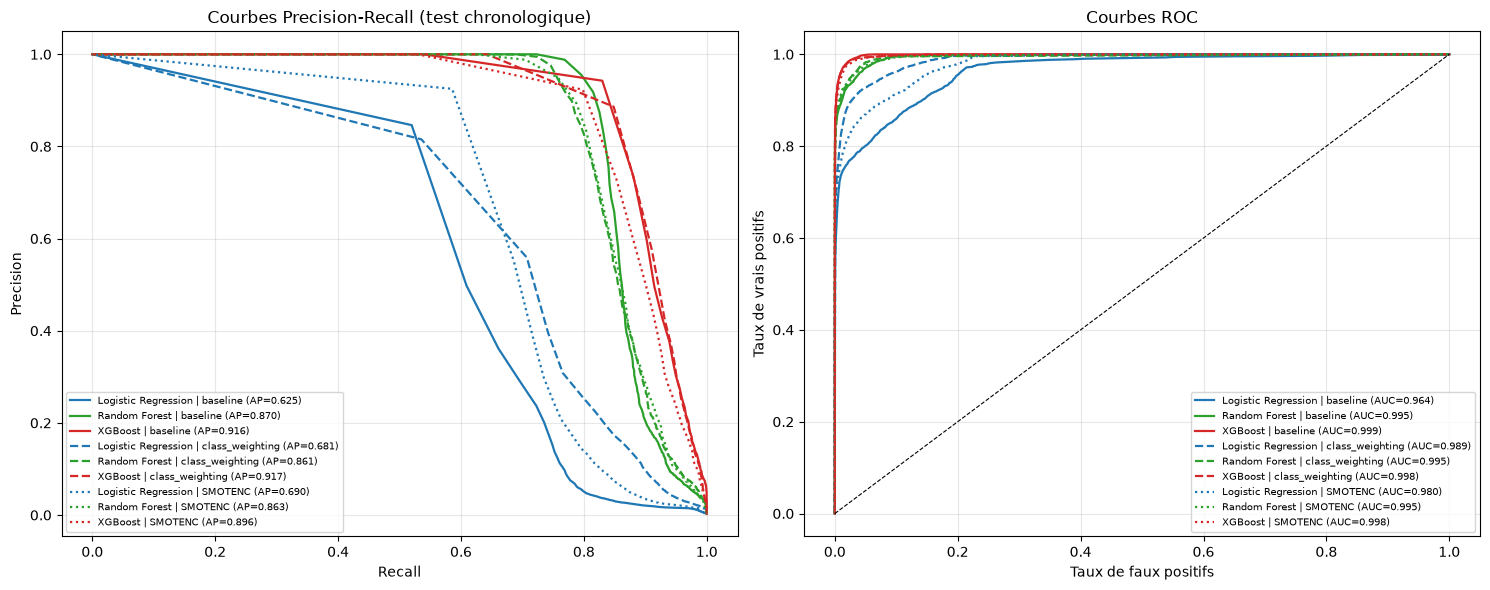

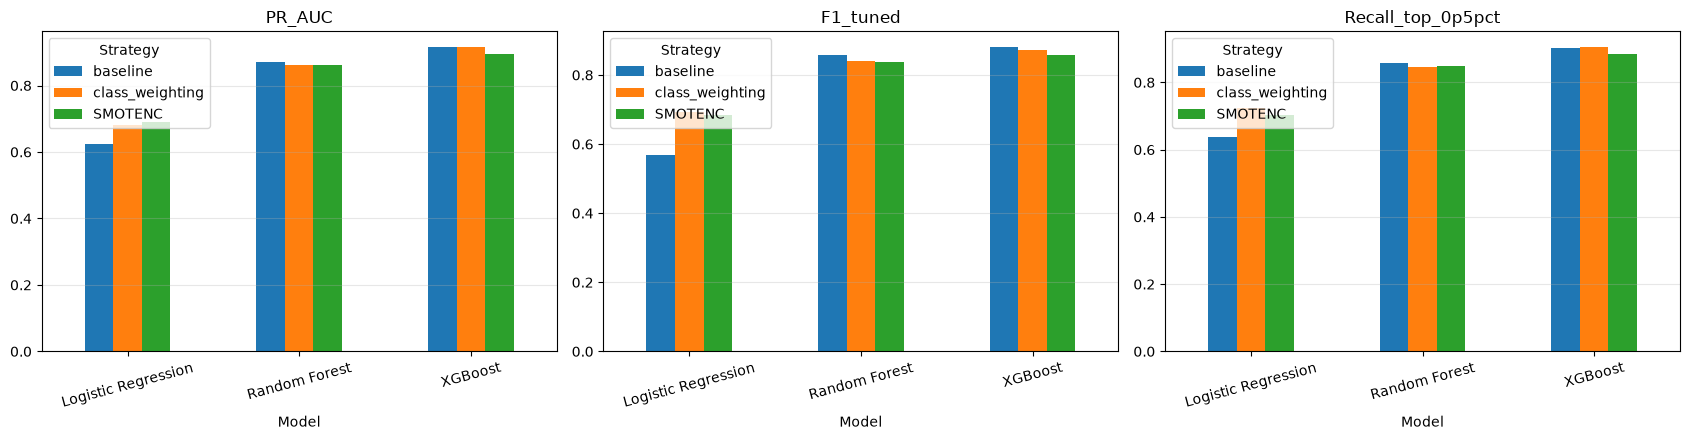

In [7]:
styles = {"baseline": "-", "class_weighting": "--", "SMOTENC": ":"}
colors = {"Logistic Regression": "tab:blue", "Random Forest": "tab:green", "XGBoost": "tab:red"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for row in all_results:
    label = f"{row['Model']} | {row['Strategy']}"
    scores = test_scores[label]
    p, r, _ = precision_recall_curve(y_test, scores)
    r_d, p_d = _downsample(r, p)
    fpr, tpr, _ = roc_curve(y_test, scores)
    f_d, t_d = _downsample(fpr, tpr)
    kw = dict(ls=styles[row["Strategy"]], color=colors[row["Model"]], lw=1.6,
              label=f"{label} (AP={row['PR_AUC']:.3f})")
    axes[0].plot(r_d, p_d, **kw)
    axes[1].plot(f_d, t_d, **{**kw, "label": f"{label} (AUC={row['ROC_AUC']:.3f})"})
axes[0].set(xlabel="Recall", ylabel="Precision", title="Courbes Precision-Recall (test chronologique)")
axes[1].set(xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs", title="Courbes ROC")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["PR_AUC", "F1_tuned", "Recall_top_0p5pct"]):
    results_df.pivot(index="Model", columns="Strategy", values=metric)[STRATEGIES].plot.bar(ax=ax, rot=15)
    ax.set_title(metric)
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

## 5. Effet du seuil et budget d'alertes

Meilleur modèle (PR-AUC) : XGBoost | class_weighting


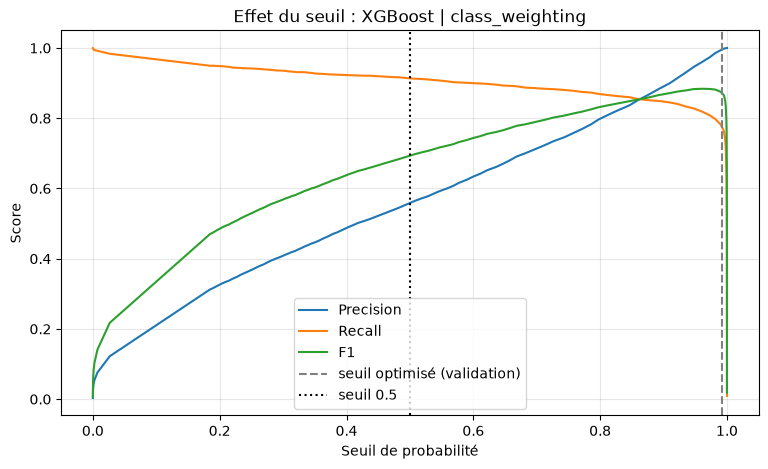


Budget d'alertes -> fraudes retrouvées :
  top 0.1 % des scores : recall 0.304 | precision 1.000
  top 0.5 % des scores : recall 0.907 | precision 0.597
  top 1 % des scores : recall 0.950 | precision 0.313


In [8]:
best = results_df.iloc[0]
label = f"{best['Model']} | {best['Strategy']}"
print(f"Meilleur modèle (PR-AUC) : {label}")

table = threshold_table(y_test, test_scores[label])
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(table["threshold"], table["Precision"], label="Precision")
ax.plot(table["threshold"], table["Recall"], label="Recall")
ax.plot(table["threshold"], table["F1"], label="F1")
ax.axvline(best["Tuned_threshold"], color="gray", ls="--", label="seuil optimisé (validation)")
ax.axvline(0.5, color="black", ls=":", label="seuil 0.5")
ax.set(xlabel="Seuil de probabilité", ylabel="Score", title=f"Effet du seuil : {label}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("\nBudget d'alertes -> fraudes retrouvées :")
for f in TOP_K_FRACTIONS:
    k = _frac_name(f)
    print(f"  top {f * 100:g} % des scores : recall {best[f'Recall_top_{k}pct']:.3f} | "
          f"precision {best[f'Precision_top_{k}pct']:.3f}")

## 6. Classement lu depuis MLflow et export pour le tableau de bord

In [9]:
# Classement lu directement dans MLflow : c'est exactement ce que lira le tableau de bord
leaderboard = load_leaderboard()
display(leaderboard[leaderboard["family"] == "supervised"].round(4).head(15))

Path("results").mkdir(exist_ok=True)
leaderboard.to_csv("results/leaderboard.csv", index=False)
print("Exporté : results/leaderboard.csv")
print("Interface MLflow : mlflow ui --backend-store-uri sqlite:///mlflow.db")

,run_id,run_name,family,model,strategy,purpose,contamination,is_reference,feature_set,batch_id,...,Alert_rate,Recall_top_0p1pct,Precision_top_0p1pct,Recall_top_0p5pct,Recall_top_1pct,Precision_tuned,Recall_tuned,F1_tuned,Training_time_sec,Prediction_time_sec
0,7dac84a937344e59b239b8a98af04d97,class_weighting_XGBoost,supervised,XGBoost,class_weighting,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0054,0.3039,1.0000,0.9065,0.9495,0.9964,0.7757,0.8723,6.7061,0.7477
1,a754ce48b21d48dba7f5c4bf552de02a,baseline_XGBoost,supervised,XGBoost,baseline,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0026,0.3039,1.0000,0.9025,0.9486,0.9918,0.7945,0.8823,5.7040,0.7268
2,d5e994d189ac4ceba34db38a37b263f3,SMOTENC_XGBoost,supervised,XGBoost,SMOTENC,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0046,0.3039,1.0000,0.8849,0.9314,0.9914,0.7553,0.8574,11.4287,0.7421
3,c6c104238dbc41a88dad9fdab64c9d15,baseline_Random_Forest,supervised,Random Forest,baseline,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0024,0.3039,1.0000,0.8565,0.8837,0.9935,0.7560,0.8586,18.9355,1.2718
4,c86cdb7527024d7a807d96ce6a4dae8d,SMOTENC_Random_Forest,supervised,Random Forest,SMOTENC,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0036,0.3039,1.0000,0.8499,0.8971,0.9783,0.7313,0.8370,27.5209,1.2426
5,aaa3085c9d794db68ab8899c58c53963,class_weighting_Random_Forest,supervised,Random Forest,class_weighting,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0051,0.3039,1.0000,0.8471,0.8955,0.9877,0.7325,0.8412,23.7669,1.2253
6,e36e09f0df3843dca64361d7bd1895b3,SMOTENC_Logistic_Regression,supervised,Logistic Regression,SMOTENC,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0053,0.2919,0.9606,0.7027,0.7501,0.9425,0.5388,0.6856,7.3604,0.4615
7,e7f93cbf62304900a910fbbc877e21f0,class_weighting_Logistic_Regression,supervised,Logistic Regression,class_weighting,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0754,0.2816,0.9266,0.7233,0.7952,0.8159,0.6036,0.6938,2.6473,0.4384
8,36bd9115ca0041079e62aac2f95eb543,baseline_Logistic_Regression,supervised,Logistic Regression,baseline,model_comparison,NaN,true,pre_transaction,20261030_220326,...,0.0008,0.3037,0.9992,0.6362,0.7219,0.9640,0.4023,0.5677,1.7307,0.4602


Exporté : results/leaderboard.csv
Interface MLflow : mlflow ui --backend-store-uri sqlite:///mlflow.db


## Contrat MLflow pour le tableau de bord

Les deux notebooks écrivent dans la même expérience (`Fraud_Detection_Experiments`) avec le même schéma :

| Élément | Contenu |
|---|---|
| **Tags** | `family` (supervised / unsupervised), `model`, `strategy`, `purpose`, `feature_set`, `is_reference`, `dataset_version`, `batch_id`, `run_key`, `contamination` (non supervisé) |
| **Métriques sans seuil** | `PR_AUC`, `ROC_AUC`, `Recall_top_0p1pct`, `Precision_top_0p1pct`, `Recall_top_0p5pct`, `Recall_top_1pct`... |
| **Métriques au seuil principal** | `Precision`, `Recall`, `F1`, `MCC`, `TP`, `FP`, `FN`, `TN`, `Alerts`, `Alert_rate`, `Amount_Recall` |
| **Métriques au seuil optimisé** (supervisé) | mêmes noms avec le suffixe `_tuned`, plus `Tuned_threshold` |
| **Temps** | `Training_time_sec`, `Prediction_time_sec` |
| **Artefacts** (`evaluation/`) | `confusion_matrix*.png/.csv`, `pr_curve.png`, `pr_curve_points.csv`, `roc_curve_points.csv`, `threshold_table.csv`, `feature_importance.csv` |
| **Modèle** | pipeline complet (`model/`) |

`threshold_table.csv`, `pr_curve_points.csv` et `roc_curve_points.csv` permettent au tableau de bord de superposer les courbes et d'animer un curseur de seuil sans recharger les modèles.